# NOMe-HiC GM12878 QC plots (gm_sc_new)

QC summary and histograms for the cells processed under this workdir
(`gm_sc_new/`), using the same logic as [`../snakemake/qc_plots.ipynb`]
(`../snakemake/qc_plots.ipynb`) (`summarize_cellline_qc_from_data`).

**Dataset:** 188 cells = 47 samples (`scNH_GM_4plex_*_S*`) x 4 barcodes
(ATCACG / CGATGT / GCCAAT / TGACCA). Single 4plex GM12878 run, so all cells
are treated as one "batch" (`scNH_GM_4plex`).

**Inputs (per cell):**
- `04.alignment_snakemake/{prefix}.summary.txt.gz` — Hi-C alignment stats
- `07.bistools_snakemake/qc/{prefix}/{prefix}.calmd.trinuc_methy.{chrM,chr21}.txt.gz` — methylation QC
- `07.bistools_snakemake/methylation/{prefix}/{prefix}.cyt.filtered.sort.{GCH,HCG}.6plus2.bed.gz` — GCH/HCG site counts
- `07.bistools_snakemake/WCG/{prefix}/{prefix}.calmd.cytosine.filtered.sort.WCG.6plus2.bed.gz` — WCG loci counts

**Outputs:** `QC/` tables, `figures/cellline_summary.pdf` (+ `_p99`),
`QC/cellline_passed.txt`, per-batch overlay/violin PDFs under `figures/`, and
`QC/methylation_matrices/methylation_matrix_{GCH,HCG}_{bin}.tsv.gz`.

**NOTE vs snakemake:** trinuc files and the 6plus2 BEDs are gzipped here; the
per-cell aggregate tables are built from scratch (none were pre-saved here).
GCH/HCG counts come from the BisSNP-1.0.1 `.cyt.filtered.sort.` BEDs. The
superseded BisSNP-0.90 `.calmd.cytosine.filtered.sort.` BEDs are still on disk
and report ~2.3x fewer loci. WCG is the one exception: `bissnp_nomehic_usage.pl`
emits only GCH/HCG, so the WCG counts remain BisSNP-0.90 and are plotted for QC
only — they are not reported in the supplementary table.


In [1]:
import gzip
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
from matplotlib.backends.backend_pdf import PdfPages
from tqdm.auto import tqdm

WORKDIR = Path('/gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/gm_sc_new')
os.chdir(WORKDIR)

ALIGN_DIR = WORKDIR / '04.alignment_snakemake'
QC_DIR = WORKDIR / '07.bistools_snakemake' / 'qc'
METH_DIR = WORKDIR / '07.bistools_snakemake' / 'methylation'
WCG_DIR = WORKDIR / '07.bistools_snakemake' / 'WCG'
OUT_QC = WORKDIR / 'QC'
OUT_FIG = WORKDIR / 'figures'
OUT_QC.mkdir(exist_ok=True)
OUT_FIG.mkdir(exist_ok=True)

with open('configs/config.yaml') as f:
    CFG = yaml.safe_load(f)

THRESHOLDS = {
    'fragnum_threshold': CFG['fragnum_threshold'],
    'noncpg_threshold': CFG['noncpg_threshold'],
    'GCH_threshold': CFG['GCH_threshold'],
    'HCG_threshold': CFG['HCG_threshold'],
    'transrate_threshold': CFG['transrate_threshold'],
    'cis1kbnum_threshold': CFG['cis1kbnum_threshold'],
    # not set in this project's config -> sensible defaults
    'reads_mapq30_threshold': CFG.get('reads_mapq30_threshold', 100000),
    # Upper bound on cisnum to drop suspected doublets (inf = disabled)
    'cisnum_max_threshold': CFG.get('cisnum_max_threshold', float('inf')),
}
print('Workdir:', WORKDIR)
print('QC thresholds:', THRESHOLDS)


Workdir: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/gm_sc_new
QC thresholds: {'fragnum_threshold': 80000, 'noncpg_threshold': 5, 'GCH_threshold': 1000000, 'HCG_threshold': 150000, 'transrate_threshold': 0.7, 'cis1kbnum_threshold': 2000, 'reads_mapq30_threshold': 100000, 'cisnum_max_threshold': inf}


In [2]:
def summarize_cellline_qc_from_data(
    prefixes,
    gch_hcg_df,
    chrm_df,
    chr21_df,
    summary_files,
    dataset_label='mixed cellline',
    output_file=None,
    summary_pdf=None,
    utilized_cell_output=None,
    fragnum_threshold=800000,
    noncpg_threshold=3,
    GCH_threshold=1_000_000,
    HCG_threshold=150_000,
    transrate_threshold=0.7,
    cis1kbnum_threshold=2000,
    reads_mapq30_threshold=10000,
    cisnum_max_threshold=float('inf'),   # upper bound to drop suspected doublets
    show_inline=False,
    summary_pdf_p99=None,
    clip_percentile_p99=99,
    clip_only_if_outlier=True,
):
    """
    Summarize QC metrics from in-memory data for NOMe-HiC cellline analysis.
    Returns (df_all, df_passed).
    """

    def plot_hist(
        df,
        column,
        title,
        xlabel,
        pdf=None,
        threshold=None,
        clip_percentile=None,
        clip_only_if_outlier=False,
    ):
        plt.figure(figsize=(8, 5))
        subset = df[column].dropna()
        if subset.empty:
            plt.close()
            return

        plot_vals = subset
        title_use = title
        bins = 50

        if clip_percentile is not None:
            x_hi = np.percentile(subset, clip_percentile)
            n_above = int((subset > x_hi).sum())
            apply_clip = n_above > 0 if clip_only_if_outlier else True
            if apply_clip:
                plot_vals = subset[subset <= x_hi]
                x_lo = plot_vals.min()
                bins = np.linspace(x_lo, x_hi, 51)
                if n_above > 0:
                    title_use = (
                        f"{title} (x <= p{clip_percentile:.0f}={x_hi:.4g}; "
                        f"{n_above} above)"
                    )

        plt.hist(
            plot_vals,
            bins=bins,
            alpha=0.7,
            color='steelblue',
            edgecolor='black',
        )
        if threshold is not None:
            plt.axvline(
                threshold,
                color='red',
                linestyle='--',
                linewidth=1.5,
                label='threshold',
            )
        plt.title(title_use)
        plt.xlabel(xlabel)
        plt.ylabel('Frequency')
        if threshold is not None:
            plt.legend()
        if pdf:
            pdf.savefig()
        if show_inline:
            plt.show()
        plt.close()
    chrm_df.columns = ['noncpg_chrM','endo_chrM','exo_chrM']
    # --- Parse summaries ---
    all_entries = []
    for prefix, summ_path in tqdm(zip(prefixes, summary_files), total=len(prefixes), desc="Parsing QC summaries"):
        entry = {"prefix": prefix, "dataset": dataset_label}
        try:
            align_df = pd.read_csv(summ_path, sep='\t', header=None)
            entry.update({
                'uniquemap': float(align_df[align_df[0]=='UniqMapped:'][2].values[0].strip('%')),
                'mapq30rate': float(align_df[align_df[0]=='UniqMappedMapQ30:'][2].values[0].strip('%')),
                'mapq30num': int(align_df[align_df[0]=='UniqMappedMapQ30:'][1].values[0]),
                'fragnum': int(align_df[align_df[0]=='TotalFragments:'][1].values[0]),
                'cisnum':int(align_df[align_df[0]=='UniqMappedMapQ30NoPcrCis:'][1].values[0]),
                'cis1kbnum': int(align_df[align_df[0]=='UniqMappedMapQ30NoPcrCisMore1kb:'][1].values[0]),
                'transnum': int(align_df[align_df[0]=='UniqMappedMapQ30NoPcrTrans:'][1].values[0]),
                'cis1kbrate': float(align_df[align_df[0]=='UniqMappedMapQ30NoPcrCisMore1kb:'][2].values[0].strip('%')),
                'transrate': float(align_df[align_df[0]=='UniqMappedMapQ30NoPcrTrans:'][2].values[0].strip('%')),
            })
        except Exception:
            entry.update({k: np.nan for k in [
                'uniquemap','mapq30rate','mapq30num','fragnum','cisnum','cis1kbnum','transnum','cis1kbrate','transrate'
            ]})

        # Add methylation and GCH/HCG data
        if prefix in chrm_df.index:
            entry.update(chrm_df.loc[prefix].to_dict())
        else:
            entry.update({'noncpg_chrM': np.nan, 'endo_chrM': np.nan, 'exo_chrM': np.nan})

        if prefix in chr21_df.index:
            entry.update(chr21_df.loc[prefix].to_dict())
        else:
            entry.update({'noncpg': np.nan, 'endo': np.nan, 'exo': np.nan})

        if prefix in gch_hcg_df.index:
            entry.update(gch_hcg_df.loc[prefix].to_dict())
        else:
            entry.update({'GCH': np.nan, 'HCG': np.nan, 'WCG': np.nan})

        all_entries.append(entry)

    df = pd.DataFrame(all_entries)

    # --- Save summary table ---
    if output_file:
        df.to_csv(output_file, sep='\t', index=False)
        print(f"Saved summary table: {output_file}")

    # --- Plot histograms ---
    plot_columns = [
        ('fragnum', 'Raw fragment number', '# of fragments'),
        ('uniquemap', 'Unique mapping rate', 'Mapping rate (%)'),
        ('mapq30rate', 'Fragments MAPQ>30 rate', 'MAPQ>30 (%)'),
        ('mapq30num', 'Reads passing MAPQ>30', '# of reads'),
        ('cisnum', 'Cis interactions for Hi-C', '# of cis interactions'),
        ('transnum', 'Trans interactions for Hi-C', '# of trans interactions'),
        ('cis1kbnum', 'Cis interactions >1kb Hi-C', '# of cis interactions'),
        ('transrate', 'Trans interaction rate Hi-C', 'Trans rate (%)'),
        ('cis1kbrate', 'Cis >1kb interaction rate Hi-C', 'Cis >1kb rate (%)'),
        ('noncpg_chrM', 'Non-CpG methylation rate', '% methylation'),
        ('endo_chrM', 'Endogenous methylation rate', '% methylation'),
        ('exo_chrM', 'Exogenous methylation rate', '% methylation'),
        ('noncpg', 'Non-CpG methylation rate', '% methylation'),
        ('endo', 'Endogenous methylation rate', '% methylation'),
        ('exo', 'Exogenous methylation rate', '% methylation'),
        ('GCH', 'Number of GCH sites', 'Number of sites'),
        ('HCG', 'Number of HCG sites', 'Number of sites'),
        ('WCG', 'Number of WCG loci', 'Number of loci')
    ]
    thresholds = {
        'fragnum': fragnum_threshold,
        'noncpg': noncpg_threshold,
        'noncpg_chrM': noncpg_threshold,
        'GCH': GCH_threshold,
        'HCG': HCG_threshold,
        'transrate': transrate_threshold,
        'cis1kbnum': cis1kbnum_threshold,
        'mapq30num': reads_mapq30_threshold,
    }

    pdf_jobs = []
    if summary_pdf:
        pdf_jobs.append((summary_pdf, None, False, False))
    if summary_pdf_p99:
        pdf_jobs.append(
            (summary_pdf_p99, clip_percentile_p99, True, clip_only_if_outlier)
        )

    for pdf_path, clip_p, show, clip_if_out in pdf_jobs:
        with PdfPages(pdf_path) as pdf:
            for col, title, xlabel in plot_columns:
                plot_hist(
                    df,
                    col,
                    title,
                    xlabel,
                    pdf,
                    thresholds.get(col),
                    clip_percentile=clip_p,
                    clip_only_if_outlier=clip_if_out,
                )
        print(f"Saved summary PDF: {pdf_path}")

    if show_inline and not pdf_jobs:
        for col, title, xlabel in plot_columns:
            plot_hist(df, col, title, xlabel, None, thresholds.get(col))
    elif show_inline and pdf_jobs:
        for col, title, xlabel in plot_columns:
            plot_hist(
                df,
                col,
                title,
                xlabel,
                None,
                thresholds.get(col),
                clip_percentile=clip_percentile_p99 if summary_pdf_p99 else None,
                clip_only_if_outlier=clip_only_if_outlier,
            )

    # --- Filtering ---
    df_filtered = df[
        (df['fragnum'] > fragnum_threshold) &
        (df['noncpg'] < noncpg_threshold) &        # chr21 (autosome) non-CpG
        (df['noncpg_chrM'] < noncpg_threshold) &   # chrM non-CpG (bisulfite conversion)
        (df['GCH'] > GCH_threshold) &
        (df['HCG'] > HCG_threshold) &
        (df['transrate'] > transrate_threshold) &
        (df['cis1kbnum'] > cis1kbnum_threshold) &
        (df['cisnum'] < cisnum_max_threshold)   # upper bound, drops doublets
    ]

    if utilized_cell_output:
        df_filtered['prefix'].to_csv(utilized_cell_output, index=False, header=False)
        print(f"Saved passing cell list: {utilized_cell_output}")

    print(f"{len(df_filtered)}/{len(df)} cells passed QC thresholds")
    return df, df_filtered


In [3]:
# ADAPTED for gm_sc_new: trinuc files are gzipped here.
# GCH/HCG use the BisSNP-1.0.1 '.cyt.filtered.sort.' middle. The BisSNP-0.90
# '.calmd.cytosine.filtered.sort.' BEDs are also on disk but call ~2.3x fewer
# loci (0.90's sites are a 99.2% subset of 1.0.1's), so 1.0.1 is used.
# WCG has no 1.0.1 output -- bissnp_nomehic_usage.pl emits only GCH/HCG --
# so WCG still reads the 0.90 path, for QC plots only.
TRINUC_SUFFIX_CHRM = '.calmd.trinuc_methy.chrM.txt.gz'
TRINUC_SUFFIX_CHR21 = '.calmd.trinuc_methy.chr21.txt.gz'
BED_MIDDLE = '.cyt.filtered.sort.'
WCG_BED_MIDDLE = '.calmd.cytosine.filtered.sort.'  # BisSNP-0.90 only


def _trinuc_percent(path, trinuc):
  """Return methylation % for trinuc (e.g. ACT) from a trinuc_methy file."""
  df = pd.read_csv(path, sep='\t', header=None, names=['trinuc', 'count', 'percent'])
  vals = df.loc[df['trinuc'] == f'{trinuc}:', 'percent']
  if len(vals) == 0:
    return np.nan
  return float(str(vals.iloc[0]).strip('%'))


def build_trinuc_table(prefixes, suffix):
  rows = []
  for prefix in tqdm(prefixes, desc=f'trinuc {suffix}'):
    path = QC_DIR / prefix / f'{prefix}{suffix}'
    if not path.exists():
      rows.append([prefix, np.nan, np.nan, np.nan])
      continue
    rows.append([
      prefix,
      _trinuc_percent(path, 'ACT'),
      _trinuc_percent(path, 'ACG'),
      _trinuc_percent(path, 'GCT'),
    ])
  df = pd.DataFrame(rows, columns=['sample', 'noncpg', 'endo', 'exo'])
  return df.set_index('sample')


def _count_bed_gz(path):
  if not path.exists():
    return np.nan
  with gzip.open(path, 'rt') as f:
    return sum(1 for _ in f)


def build_gch_hcg_table(prefixes):
  # Counts covered loci per cell for GCH/HCG (under methylation/, BisSNP-1.0.1)
  # and WCG (under WCG/, BisSNP-0.90 -- no 1.0.1 WCG output exists).
  rows = []
  for prefix in tqdm(prefixes, desc='GCH/HCG/WCG counts'):
    meth_cell = METH_DIR / prefix
    gch = meth_cell / f'{prefix}{BED_MIDDLE}GCH.6plus2.bed.gz'
    hcg = meth_cell / f'{prefix}{BED_MIDDLE}HCG.6plus2.bed.gz'
    wcg = WCG_DIR / prefix / f'{prefix}{WCG_BED_MIDDLE}WCG.6plus2.bed.gz'
    rows.append([prefix, _count_bed_gz(gch), _count_bed_gz(hcg), _count_bed_gz(wcg)])
  df = pd.DataFrame(rows, columns=['sample', 'GCH', 'HCG', 'WCG'])
  return df.set_index('sample')


def discover_prefixes(qc_dir=QC_DIR):
  """All sample folders under 07.bistools_snakemake/qc that have a summary file.
  Accepts either uncompressed .summary.txt or gzipped .summary.txt.gz.
  """
  prefixes = []
  for p in sorted(qc_dir.iterdir()):
    if p.is_dir() and (
        (p / f'{p.name}.summary.txt').exists() or
        (p / f'{p.name}.summary.txt.gz').exists()
    ):
      prefixes.append(p.name)
  return prefixes


In [4]:
# Discover cells with completed bis-QC outputs
all_prefixes = discover_prefixes()
print(f'Found {len(all_prefixes)} cells with QC outputs')

# Single 4plex GM12878 run -> no batch filter, all cells used.
cellline_prefixes = all_prefixes
print(f'Using all {len(cellline_prefixes)} cells (single group)')

pd.Series(cellline_prefixes).to_csv(OUT_QC / 'cellline_prefixes_used.txt', index=False, header=False)


Found 188 cells with QC outputs
Using all 188 cells (single group)


In [5]:
# Build aggregate tables from scratch (no pre-saved tables exist in this folder).
# This reads all discovered cells; it is the main compute step.
gch_hcg_cellline = build_gch_hcg_table(cellline_prefixes)
chrm_cellline = build_trinuc_table(cellline_prefixes, TRINUC_SUFFIX_CHRM)
chr21_cellline = build_trinuc_table(cellline_prefixes, TRINUC_SUFFIX_CHR21)

gch_hcg_cellline.to_csv(OUT_QC / 'cellline.gch_hcg_count.txt', sep='\t')
chrm_cellline.to_csv(OUT_QC / 'cellline.chrM.txt', sep='\t')
chr21_cellline.to_csv(OUT_QC / 'cellline.chr21.txt', sep='\t')

display(gch_hcg_cellline.head())
display(chr21_cellline.head())


GCH/HCG/WCG counts:   0%|          | 0/188 [00:00<?, ?it/s]

trinuc .calmd.trinuc_methy.chrM.txt.gz:   0%|          | 0/188 [00:00<?, ?it/s]

trinuc .calmd.trinuc_methy.chr21.txt.gz:   0%|          | 0/188 [00:00<?, ?it/s]

,GCH,HCG,WCG
sample,,,
scNH_GM_4plex_10_S9.ATCACG,6340718,991418,601305
scNH_GM_4plex_10_S9.CGATGT,2155132,335451,204886
scNH_GM_4plex_10_S9.GCCAAT,3484123,533215,328382
scNH_GM_4plex_10_S9.TGACCA,5352849,821368,501966
scNH_GM_4plex_11_S10.ATCACG,3501650,560770,336962


,noncpg,endo,exo
sample,,,
scNH_GM_4plex_10_S9.ATCACG,1.173,43.356,68.029
scNH_GM_4plex_10_S9.CGATGT,1.212,38.619,65.616
scNH_GM_4plex_10_S9.GCCAAT,1.192,38.915,66.934
scNH_GM_4plex_10_S9.TGACCA,1.053,37.108,65.027
scNH_GM_4plex_11_S10.ATCACG,1.127,34.977,66.968


In [6]:
# (Re)load the tables saved in the previous cell
gch_hcg_cellline = pd.read_csv(OUT_QC / 'cellline.gch_hcg_count.txt', sep='\t', index_col=0)
chrm_cellline = pd.read_csv(OUT_QC / 'cellline.chrM.txt', sep='\t', index_col=0)
chr21_cellline = pd.read_csv(OUT_QC / 'cellline.chr21.txt', sep='\t', index_col=0)


In [7]:
# Alignment summaries + QC plots
prefixes = cellline_prefixes
def _summary_path(p):
    plain = ALIGN_DIR / f'{p}.summary.txt'
    gz    = ALIGN_DIR / f'{p}.summary.txt.gz'
    return str(plain if plain.exists() else gz)   # pandas auto-infers gzip from extension
summary_files = [_summary_path(p) for p in prefixes]

df_all_cellline, df_passed = summarize_cellline_qc_from_data(
    prefixes=prefixes,
    gch_hcg_df=gch_hcg_cellline,
    chrm_df=chrm_cellline,
    chr21_df=chr21_cellline,
    summary_files=summary_files,
    dataset_label='sc NOMe-HiC GM12878 (4plex)',
    output_file=str(OUT_QC / 'cellline_qc_summary.txt'),
    summary_pdf=str(OUT_FIG / 'cellline_summary.pdf'),
    summary_pdf_p99=str(OUT_FIG / 'cellline_summary_p99.pdf'),
    clip_percentile_p99=99,
    clip_only_if_outlier=True,
    utilized_cell_output=str(OUT_QC / 'cellline_passed.txt'),
    show_inline=False,
    **THRESHOLDS,
)

df_all_cellline.head()


Parsing QC summaries:   0%|          | 0/188 [00:00<?, ?it/s]

Saved summary table: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/gm_sc_new/QC/cellline_qc_summary.txt
Saved summary PDF: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/gm_sc_new/figures/cellline_summary.pdf
Saved summary PDF: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/gm_sc_new/figures/cellline_summary_p99.pdf
Saved passing cell list: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/gm_sc_new/QC/cellline_passed.txt
180/188 cells passed QC thresholds


,prefix,dataset,uniquemap,mapq30rate,mapq30num,fragnum,cisnum,cis1kbnum,transnum,cis1kbrate,transrate,noncpg_chrM,endo_chrM,exo_chrM,noncpg,endo,exo,GCH,HCG,WCG
0,scNH_GM_4plex_10_S9.ATCACG,sc NOMe-HiC GM12878 (4plex),100.0,72.900976,6925019,9499213,2363249,57536,52240,2.381961,2.162709,2.072,3.669,66.989,1.173,43.356,68.029,6340718,991418,601305
1,scNH_GM_4plex_10_S9.CGATGT,sc NOMe-HiC GM12878 (4plex),100.0,63.379764,2436848,3844836,793219,16894,19131,2.079645,2.355019,4.944,3.819,61.222,1.212,38.619,65.616,2155132,335451,204886
2,scNH_GM_4plex_10_S9.GCCAAT,sc NOMe-HiC GM12878 (4plex),100.0,63.168956,4001351,6334363,1335607,26088,32042,1.907507,2.342853,2.609,1.926,64.011,1.192,38.915,66.934,3484123,533215,328382
3,scNH_GM_4plex_10_S9.TGACCA,sc NOMe-HiC GM12878 (4plex),100.0,73.659130,6095735,8275600,2032117,45932,42562,2.213933,2.051498,3.740,4.117,61.989,1.053,37.108,65.027,5352849,821368,501966
4,scNH_GM_4plex_11_S10.ATCACG,sc NOMe-HiC GM12878 (4plex),100.0,61.302851,2705407,4413183,1219255,27277,24035,2.193937,1.933177,3.159,0.465,62.505,1.127,34.977,66.968,3501650,560770,336962


In [8]:
df_passed


,prefix,dataset,uniquemap,mapq30rate,mapq30num,fragnum,cisnum,cis1kbnum,transnum,cis1kbrate,transrate,noncpg_chrM,endo_chrM,exo_chrM,noncpg,endo,exo,GCH,HCG,WCG
0,scNH_GM_4plex_10_S9.ATCACG,sc NOMe-HiC GM12878 (4plex),100.0,72.900976,6925019,9499213,2363249,57536,52240,2.381961,2.162709,2.072,3.669,66.989,1.173,43.356,68.029,6340718,991418,601305
1,scNH_GM_4plex_10_S9.CGATGT,sc NOMe-HiC GM12878 (4plex),100.0,63.379764,2436848,3844836,793219,16894,19131,2.079645,2.355019,4.944,3.819,61.222,1.212,38.619,65.616,2155132,335451,204886
2,scNH_GM_4plex_10_S9.GCCAAT,sc NOMe-HiC GM12878 (4plex),100.0,63.168956,4001351,6334363,1335607,26088,32042,1.907507,2.342853,2.609,1.926,64.011,1.192,38.915,66.934,3484123,533215,328382
3,scNH_GM_4plex_10_S9.TGACCA,sc NOMe-HiC GM12878 (4plex),100.0,73.659130,6095735,8275600,2032117,45932,42562,2.213933,2.051498,3.740,4.117,61.989,1.053,37.108,65.027,5352849,821368,501966
4,scNH_GM_4plex_11_S10.ATCACG,sc NOMe-HiC GM12878 (4plex),100.0,61.302851,2705407,4413183,1219255,27277,24035,2.193937,1.933177,3.159,0.465,62.505,1.127,34.977,66.968,3501650,560770,336962
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
183,scNH_GM_4plex_8_S7.TGACCA,sc NOMe-HiC GM12878 (4plex),100.0,64.288277,2521500,3922177,959709,20512,24395,2.084333,2.478905,2.389,2.679,70.581,1.396,39.678,67.665,2611319,398318,245493
184,scNH_GM_4plex_9_S8.ATCACG,sc NOMe-HiC GM12878 (4plex),100.0,68.280847,3918209,5738372,1512189,56365,26332,3.663583,1.711514,2.538,3.008,59.288,1.137,35.937,73.821,4120255,637332,390638
185,scNH_GM_4plex_9_S8.CGATGT,sc NOMe-HiC GM12878 (4plex),100.0,74.492697,4478568,6012090,1657382,42120,40351,2.480955,2.376758,3.167,3.320,70.728,1.219,36.903,66.755,4558376,708733,433368
186,scNH_GM_4plex_9_S8.GCCAAT,sc NOMe-HiC GM12878 (4plex),100.0,66.927841,3511068,5246050,1333921,42499,27701,3.121204,2.034412,1.722,0.808,61.005,1.168,38.637,72.293,3641154,573045,348692


In [9]:
# Single group: all cells share one batch label
df_all_cellline['batch'] = 'scNH_GM_4plex'
passed_set = set(df_passed['prefix'])
df_all_cellline['passed'] = df_all_cellline['prefix'].isin(passed_set)

batch_summary = (
    df_all_cellline.groupby('batch')['passed']
    .agg(['sum', 'count'])
    .assign(pass_rate=lambda x: x['sum'] / x['count'])
    .rename(columns={'sum': 'n_passed', 'count': 'n_total'})
)
batch_summary


,n_passed,n_total,pass_rate
batch,,,
scNH_GM_4plex,180,188,0.957447


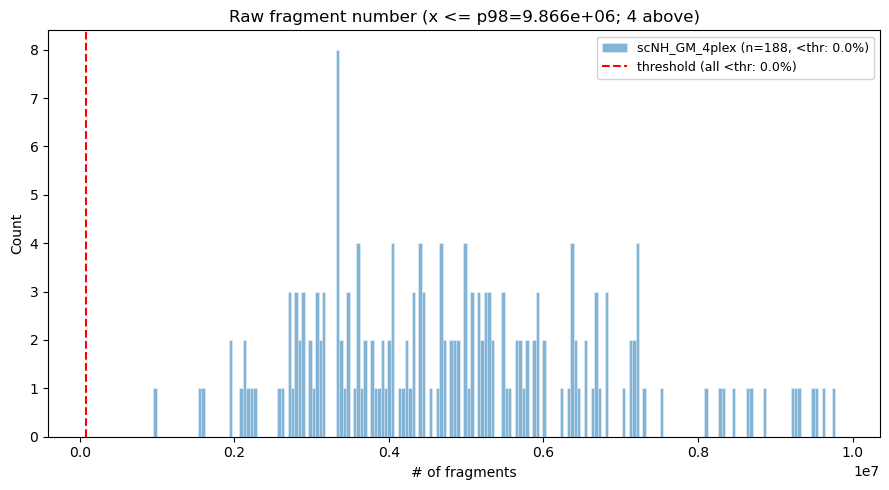

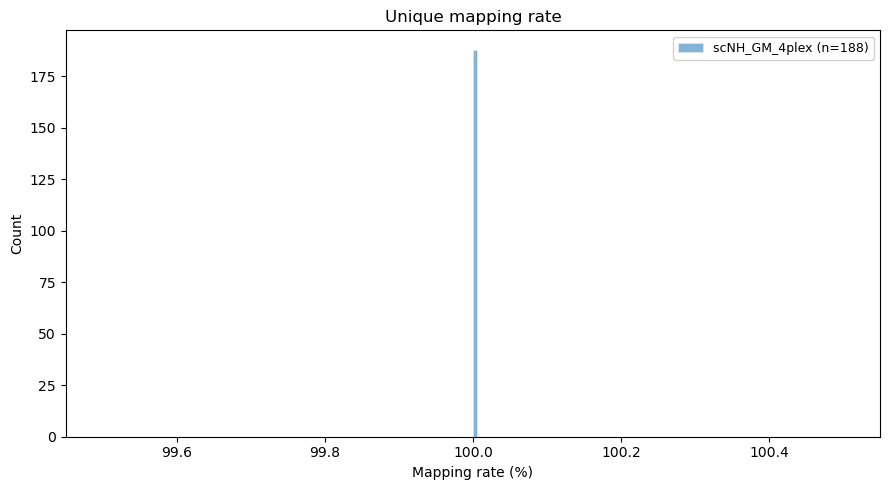

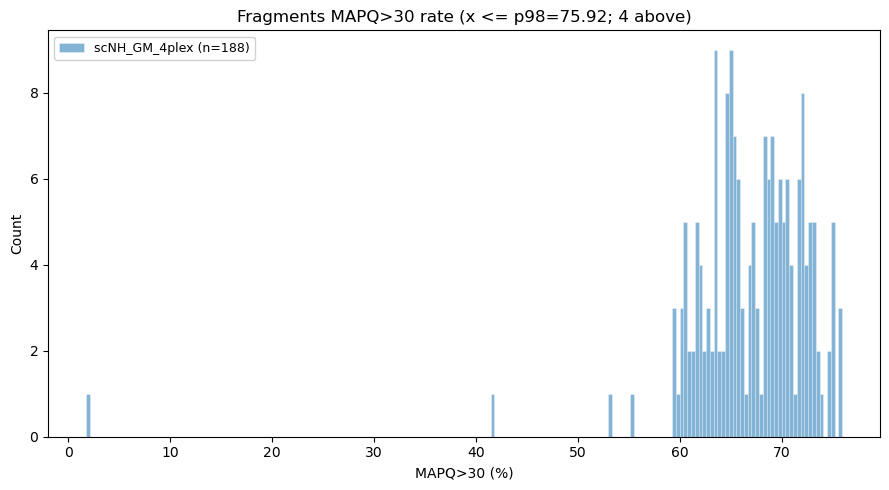

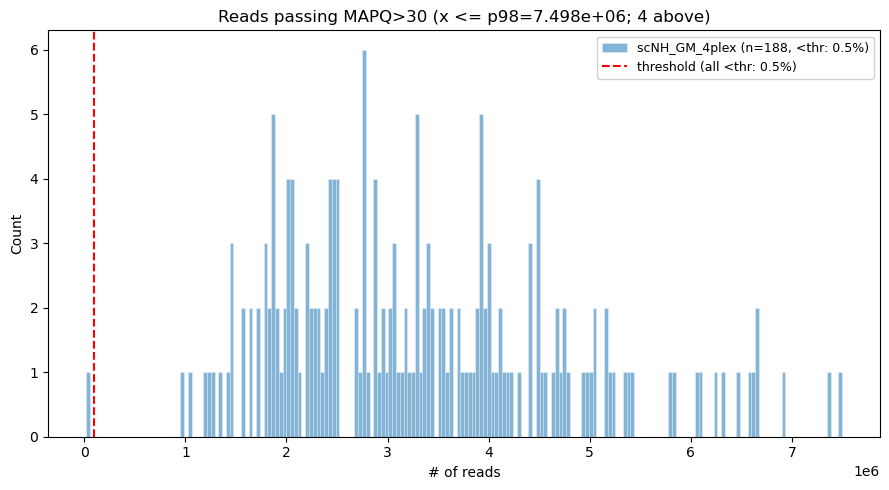

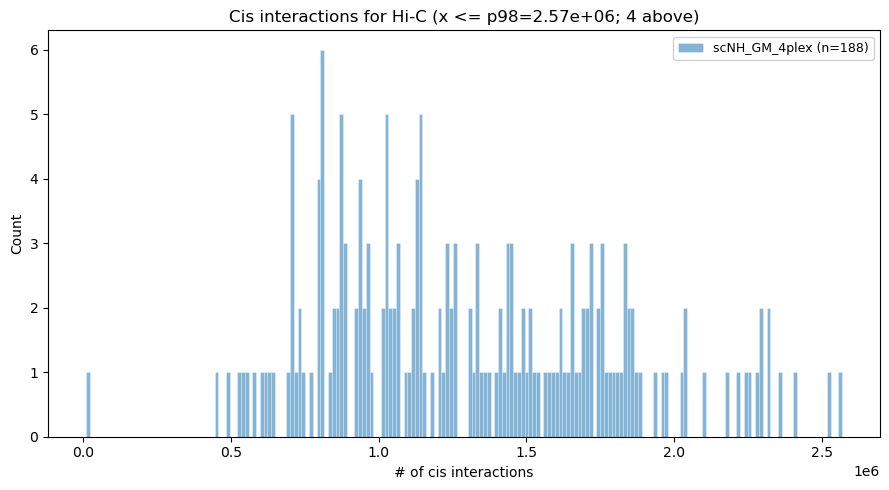

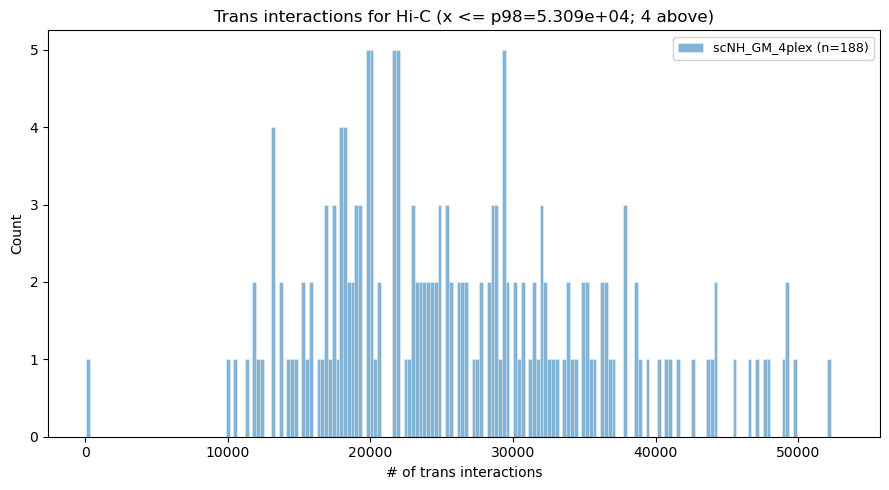

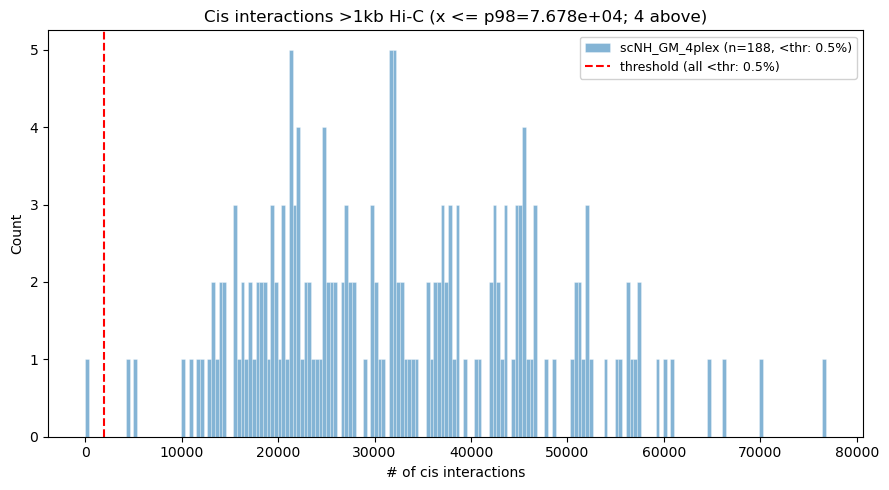

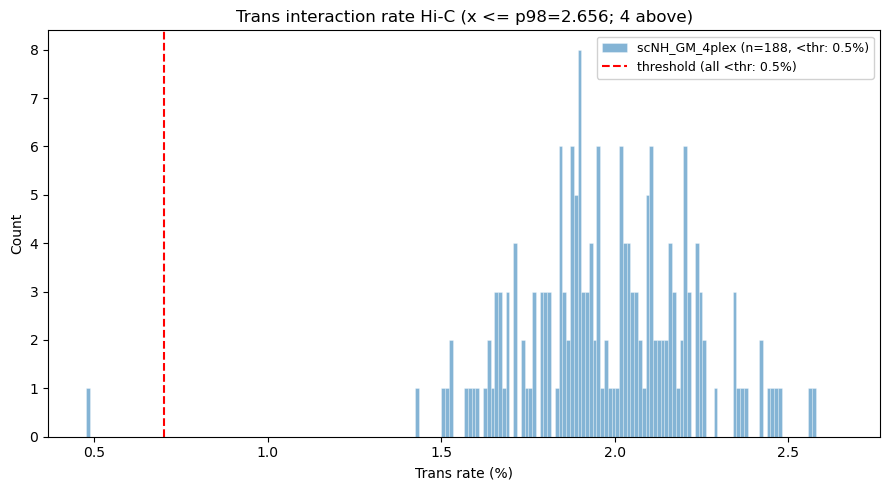

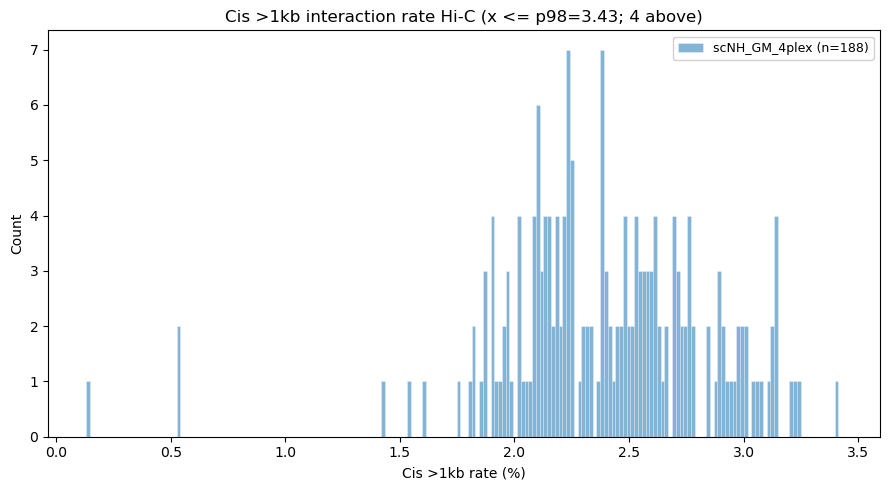

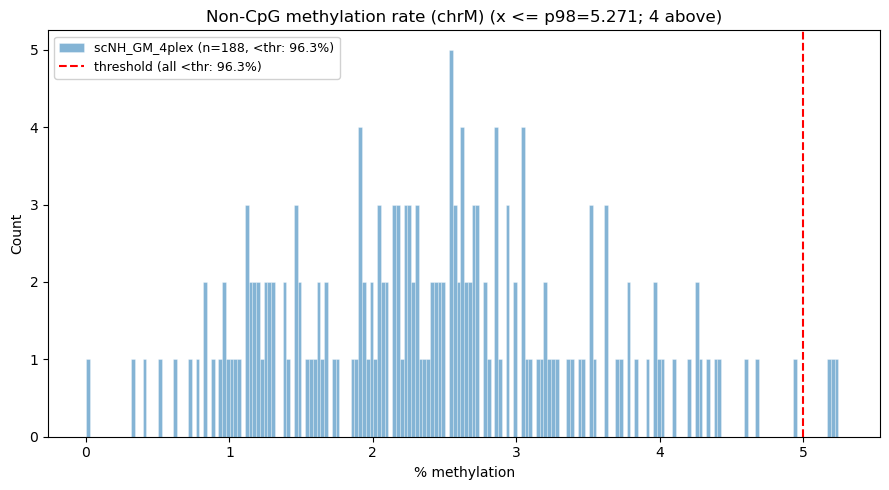

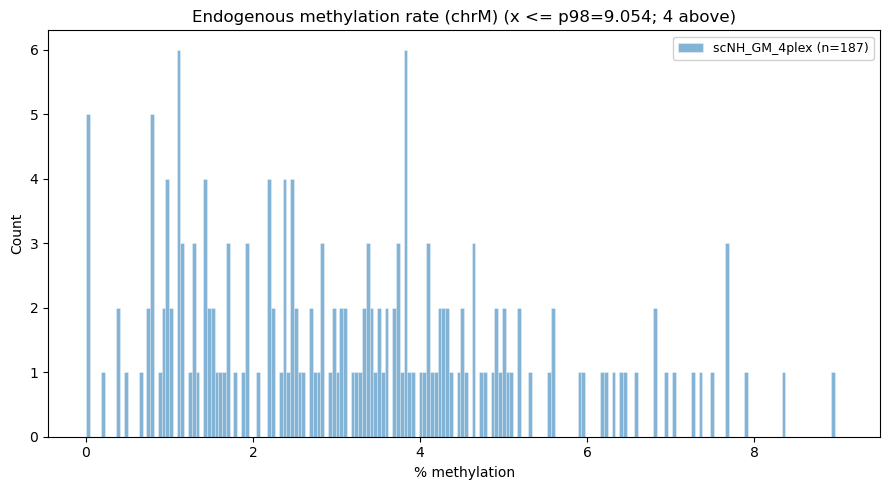

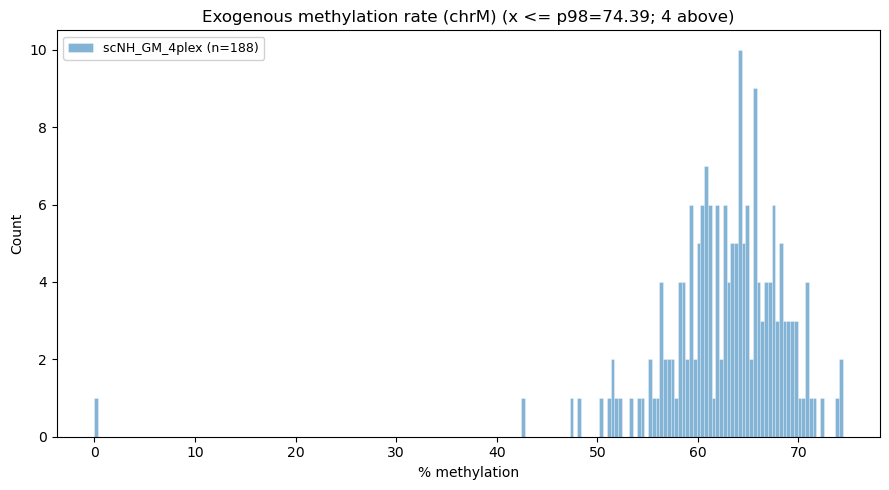

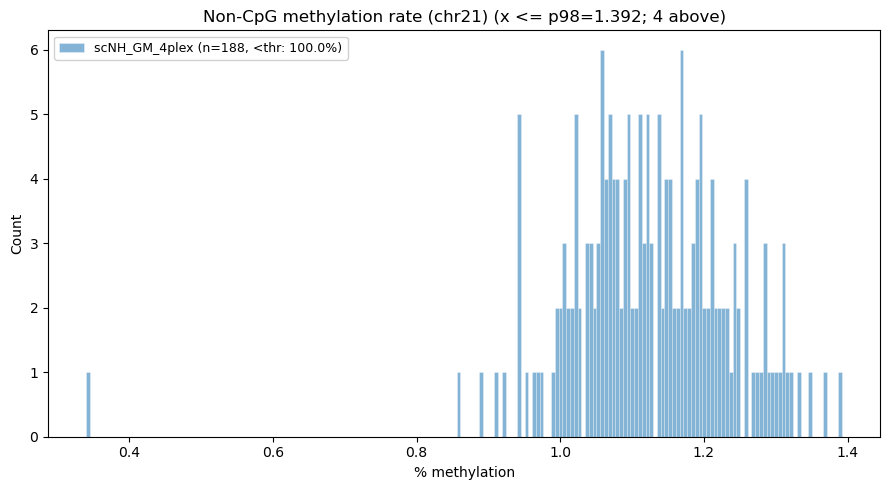

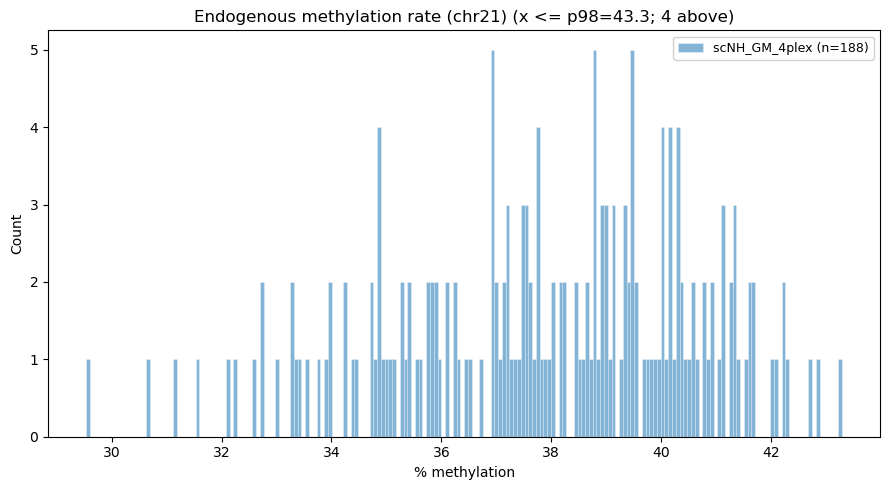

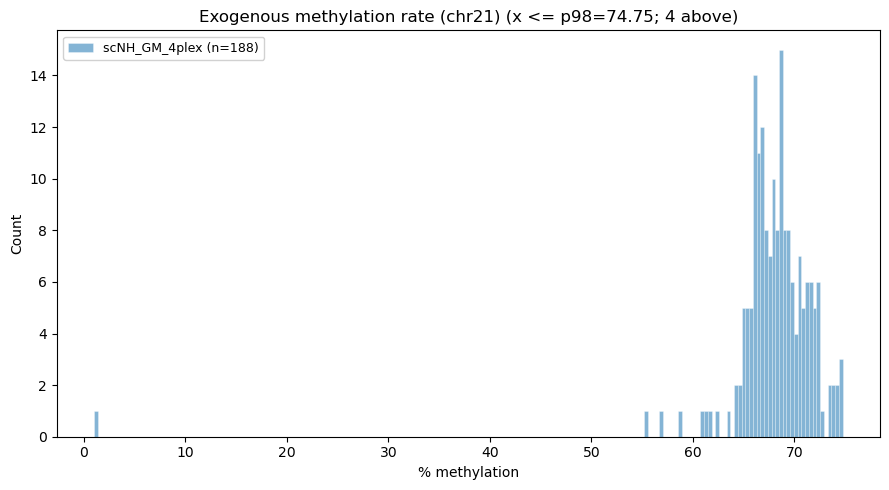

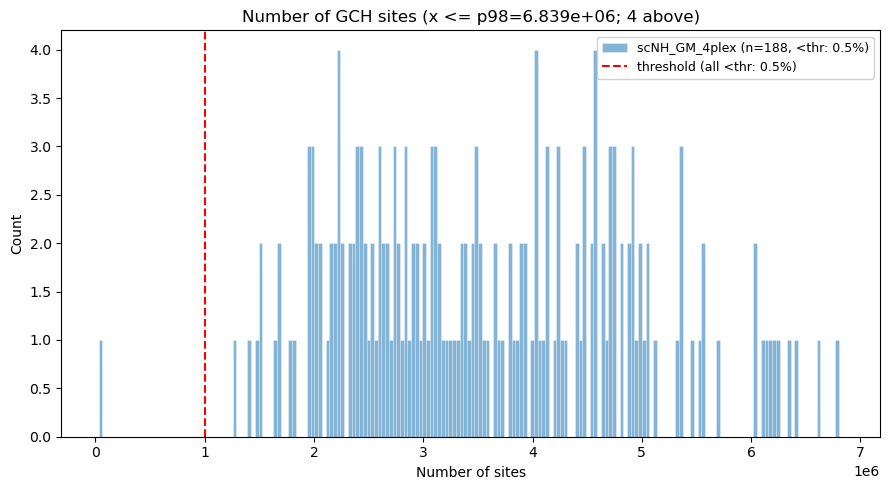

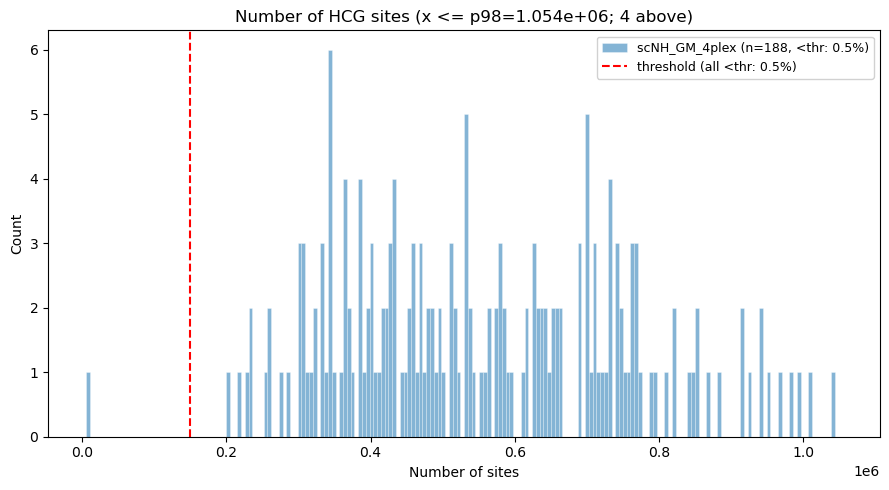

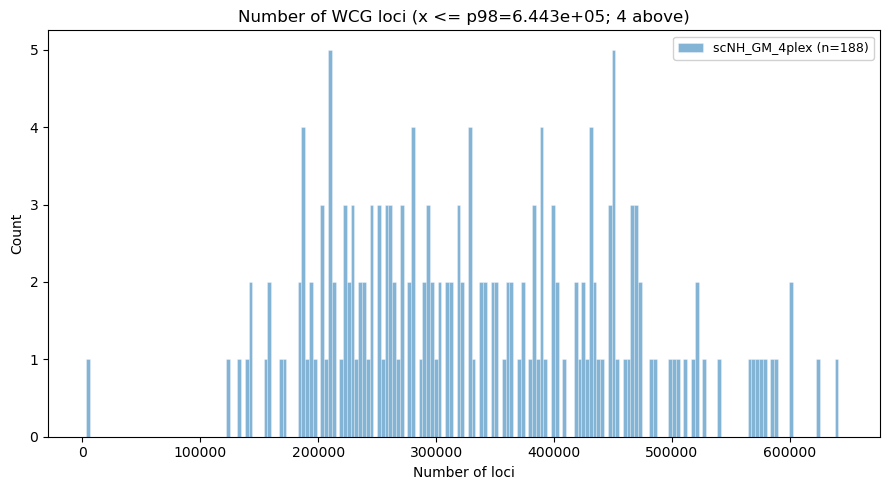

Saved overlay histograms: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/gm_sc_new/figures/cellline_summary_by_batch_p99_if_outlier.pdf


In [10]:
# Overlay histograms: one panel per metric (single group here)
PLOT_COLUMNS = [
    ('fragnum', 'Raw fragment number', '# of fragments'),
    ('uniquemap', 'Unique mapping rate', 'Mapping rate (%)'),
    ('mapq30rate', 'Fragments MAPQ>30 rate', 'MAPQ>30 (%)'),
    ('mapq30num', 'Reads passing MAPQ>30', '# of reads'),
    ('cisnum', 'Cis interactions for Hi-C', '# of cis interactions'),
    ('transnum', 'Trans interactions for Hi-C', '# of trans interactions'),
    ('cis1kbnum', 'Cis interactions >1kb Hi-C', '# of cis interactions'),
    ('transrate', 'Trans interaction rate Hi-C', 'Trans rate (%)'),
    ('cis1kbrate', 'Cis >1kb interaction rate Hi-C', 'Cis >1kb rate (%)'),
    ('noncpg_chrM', 'Non-CpG methylation rate (chrM)', '% methylation'),
    ('endo_chrM', 'Endogenous methylation rate (chrM)', '% methylation'),
    ('exo_chrM', 'Exogenous methylation rate (chrM)', '% methylation'),
    ('noncpg', 'Non-CpG methylation rate (chr21)', '% methylation'),
    ('endo', 'Endogenous methylation rate (chr21)', '% methylation'),
    ('exo', 'Exogenous methylation rate (chr21)', '% methylation'),
    ('GCH', 'Number of GCH sites', 'Number of sites'),
    ('HCG', 'Number of HCG sites', 'Number of sites'),
    ('WCG', 'Number of WCG loci', 'Number of loci'),
]

METRIC_THRESHOLDS = {
    'fragnum': THRESHOLDS['fragnum_threshold'],
    'noncpg': THRESHOLDS['noncpg_threshold'],
    'noncpg_chrM': THRESHOLDS['noncpg_threshold'],
    'GCH': THRESHOLDS['GCH_threshold'],
    'HCG': THRESHOLDS['HCG_threshold'],
    'transrate': THRESHOLDS['transrate_threshold'],
    'cis1kbnum': THRESHOLDS['cis1kbnum_threshold'],
    'mapq30num': THRESHOLDS['reads_mapq30_threshold'],
}


def plot_histograms_per_batch(
    df,
    plot_columns,
    thresholds,
    batch_order=None,
    out_pdf=None,
    bins=40,
    show_inline=False,
    clip_percentile=None,
    clip_only_if_outlier=False,
):
    """One figure per metric: batches overlaid by color."""
    if 'batch' not in df.columns:
        df = df.copy()
        df['batch'] = 'scNH_GM_4plex'
    if batch_order is None:
        batch_order = sorted(df['batch'].dropna().unique())

    batch_colors = dict(
        zip(
            batch_order,
            sns.color_palette('tab10', n_colors=max(len(batch_order), 1)),
        )
    )

    pdf = PdfPages(out_pdf) if out_pdf else None
    try:
        for col, title, xlabel in plot_columns:
            fig, ax = plt.subplots(figsize=(9, 5))
            thr = thresholds.get(col)

            all_vals = df[col].dropna()
            if all_vals.empty:
                plt.close(fig)
                continue

            title_use = title
            x_hi = None
            apply_clip = False
            if clip_percentile is not None:
                x_hi = float(np.percentile(all_vals, clip_percentile))
                n_above = int((all_vals > x_hi).sum())
                apply_clip = (n_above > 0) if clip_only_if_outlier else True
                if apply_clip:
                    x_lo = all_vals.min()
                    bin_edges = np.linspace(x_lo, x_hi, bins + 1)
                    if n_above > 0:
                        title_use = (
                            f"{title} (x <= p{clip_percentile:.0f}={x_hi:.4g}; "
                            f"{n_above} above)"
                        )
                else:
                    x_hi = None
                    bin_edges = np.histogram_bin_edges(all_vals, bins=bins)
            else:
                bin_edges = np.histogram_bin_edges(all_vals, bins=bins)

            for batch in batch_order:
                vals_full = df.loc[df['batch'] == batch, col].dropna()
                if vals_full.empty:
                    continue
                n_total = len(vals_full)
                if thr is not None and n_total > 0:
                    pct_under = 100.0 * float((vals_full < thr).sum()) / n_total
                    label = f'{batch} (n={n_total}, <thr: {pct_under:.1f}%)'
                else:
                    label = f'{batch} (n={n_total})'

                vals = vals_full
                if apply_clip and x_hi is not None:
                    vals = vals[vals <= x_hi]
                ax.hist(
                    vals,
                    bins=bin_edges,
                    alpha=0.55,
                    color=batch_colors[batch],
                    label=label,
                    edgecolor='white',
                    linewidth=0.4,
                )

            if thr is not None and (not apply_clip or thr <= x_hi):
                all_n = len(all_vals)
                pct_under_all = 100.0 * float((all_vals < thr).sum()) / all_n if all_n else 0.0
                ax.axvline(
                    thr,
                    color='red',
                    linestyle='--',
                    linewidth=1.5,
                    label=f'threshold (all <thr: {pct_under_all:.1f}%)',
                )

            ax.set_title(title_use)
            ax.set_xlabel(xlabel)
            ax.set_ylabel('Count')
            ax.legend(loc='best', fontsize=9, framealpha=0.9)
            fig.tight_layout()

            if pdf is not None:
                pdf.savefig(fig, bbox_inches='tight')
            if show_inline:
                plt.show()
            plt.close(fig)
    finally:
        if pdf is not None:
            pdf.close()

    if out_pdf is not None:
        print(f'Saved overlay histograms: {out_pdf}')


if 'batch' not in df_all_cellline.columns:
    df_all_cellline['batch'] = 'scNH_GM_4plex'

batch_order = sorted(df_all_cellline['batch'].unique())

# Cap x-axis at p98 only when outliers exist (values above p98)
plot_histograms_per_batch(
    df_all_cellline,
    PLOT_COLUMNS,
    METRIC_THRESHOLDS,
    batch_order=batch_order,
    out_pdf=OUT_FIG / 'cellline_summary_by_batch_p99_if_outlier.pdf',
    clip_percentile=98,
    clip_only_if_outlier=True,
    show_inline=True,
    bins=200,
)


In [11]:
def plot_violins_per_batch(
    df,
    plot_columns,
    thresholds,
    batch_order=None,
    out_pdf=None,
    show_inline=False,
    clip_percentile=None,
    clip_only_if_outlier=False,
):
    """One figure per metric: violin plot across batches."""

    if 'batch' not in df.columns:
        df = df.copy()
        df['batch'] = 'scNH_GM_4plex'

    if batch_order is None:
        batch_order = sorted(df['batch'].dropna().unique())

    pdf = PdfPages(out_pdf) if out_pdf else None

    try:
        for col, title, ylabel in plot_columns:
            if col not in df.columns:
                continue

            plot_df = df[['batch', col]].dropna().copy()
            plot_df = plot_df[plot_df['batch'].isin(batch_order)]

            if plot_df.empty:
                continue

            thr = thresholds.get(col)
            title_use = title

            if clip_percentile is not None:
                x_hi = float(np.percentile(plot_df[col], clip_percentile))
                n_above = int((plot_df[col] > x_hi).sum())

                apply_clip = (n_above > 0) if clip_only_if_outlier else True

                if apply_clip:
                    plot_df = plot_df[plot_df[col] <= x_hi]
                    title_use = (
                        f"{title} (<= p{clip_percentile:.0f}={x_hi:.4g}; "
                        f"{n_above} above)"
                    )

            fig, ax = plt.subplots(figsize=(10, 5))

            sns.violinplot(
                data=plot_df,
                x='batch',
                y=col,
                order=batch_order,
                inner='box',
                cut=0,
                linewidth=1,
                ax=ax,
            )

            sns.stripplot(
                data=plot_df,
                x='batch',
                y=col,
                order=batch_order,
                color='black',
                size=1.5,
                alpha=0.25,
                jitter=0.25,
                ax=ax,
            )

            if thr is not None:
                all_vals = df[col].dropna()
                pct_under_all = 100.0 * (all_vals < thr).sum() / len(all_vals)

                ax.axhline(
                    thr,
                    color='red',
                    linestyle='--',
                    linewidth=1.5,
                    label=f'threshold (all <thr: {pct_under_all:.1f}%)',
                )
                ax.legend(loc='best', fontsize=9)

            ax.set_title(title_use)
            ax.set_xlabel('Batch')
            ax.set_ylabel(ylabel)
            ax.tick_params(axis='x', rotation=45)
            fig.tight_layout()

            if pdf is not None:
                pdf.savefig(fig, bbox_inches='tight')

            if show_inline:
                plt.show()

            plt.close(fig)

    finally:
        if pdf is not None:
            pdf.close()

    if out_pdf is not None:
        print(f'Saved violin plots: {out_pdf}')


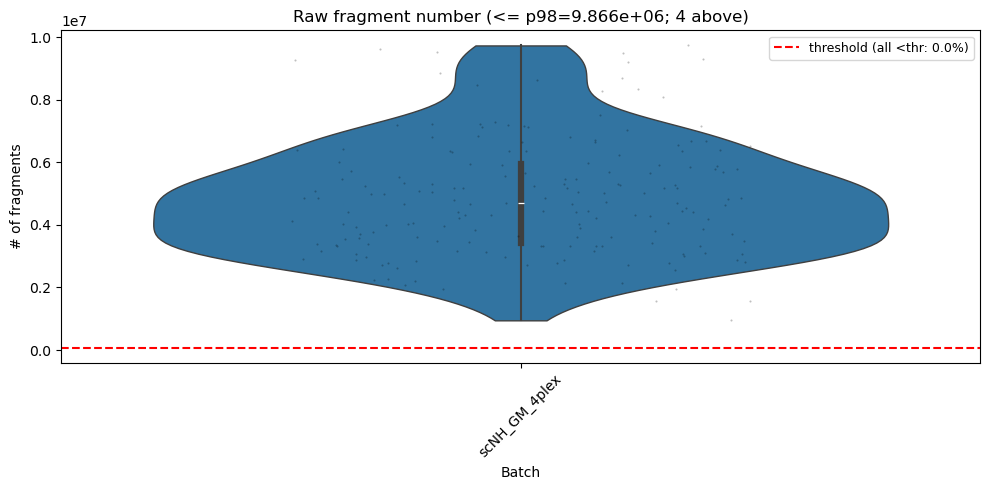

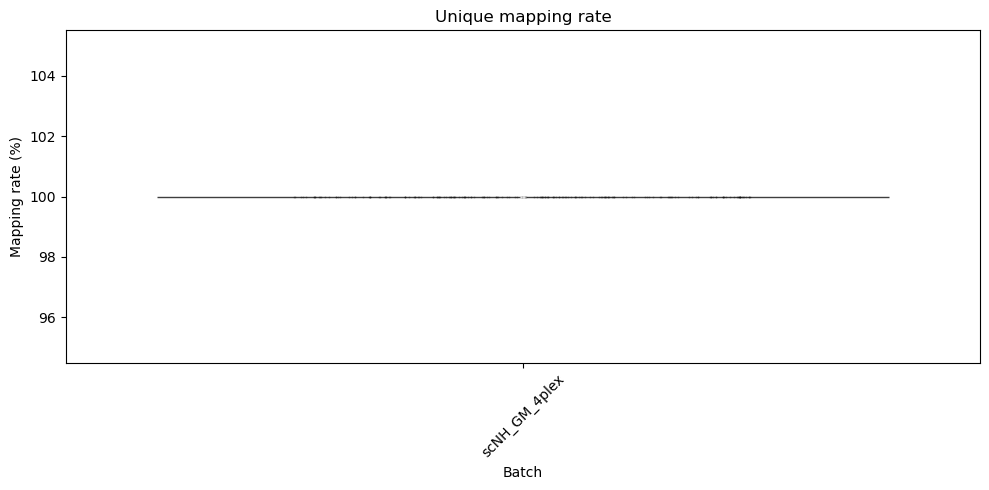

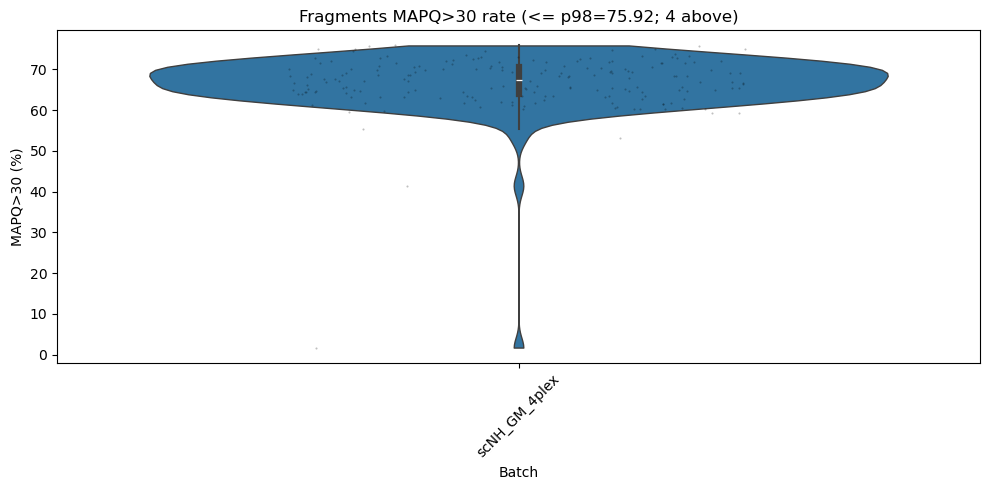

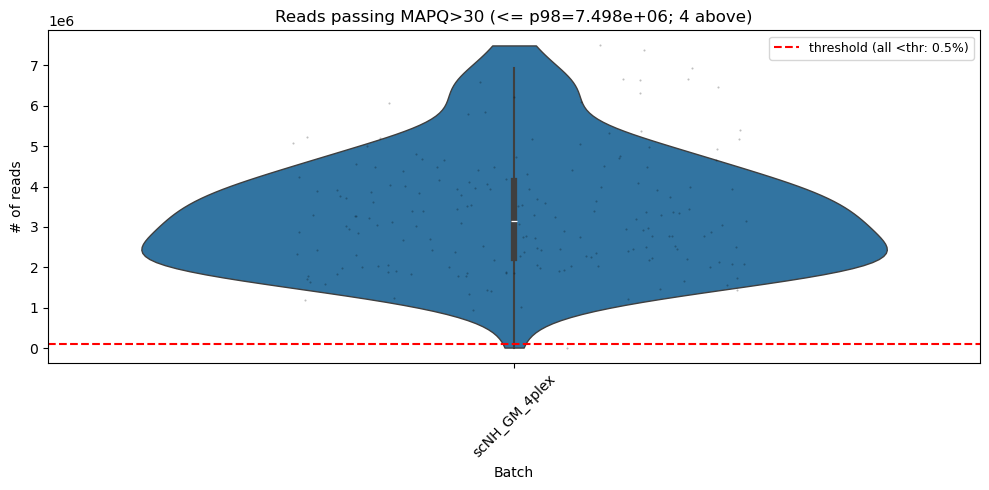

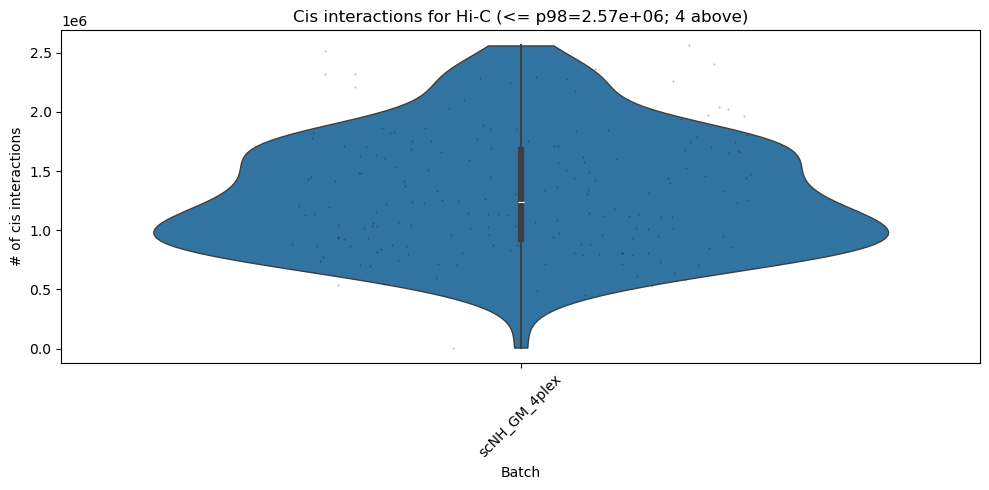

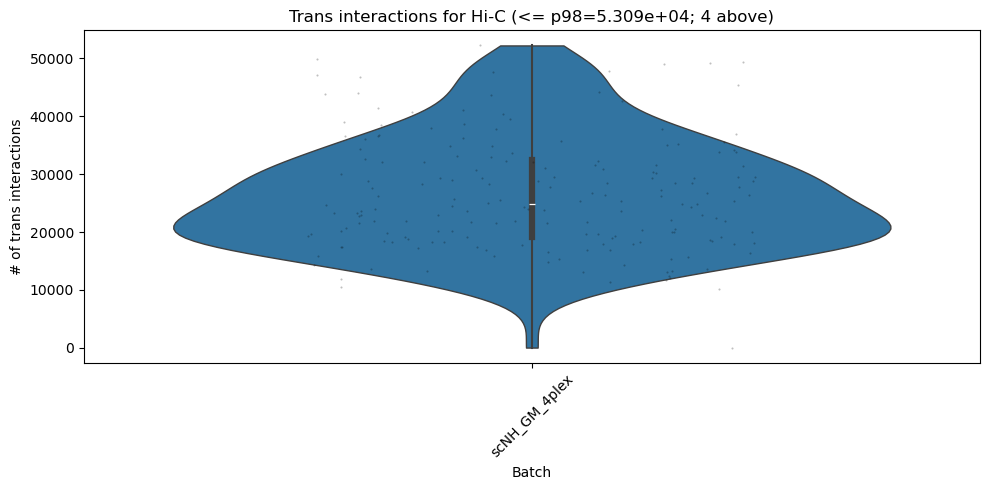

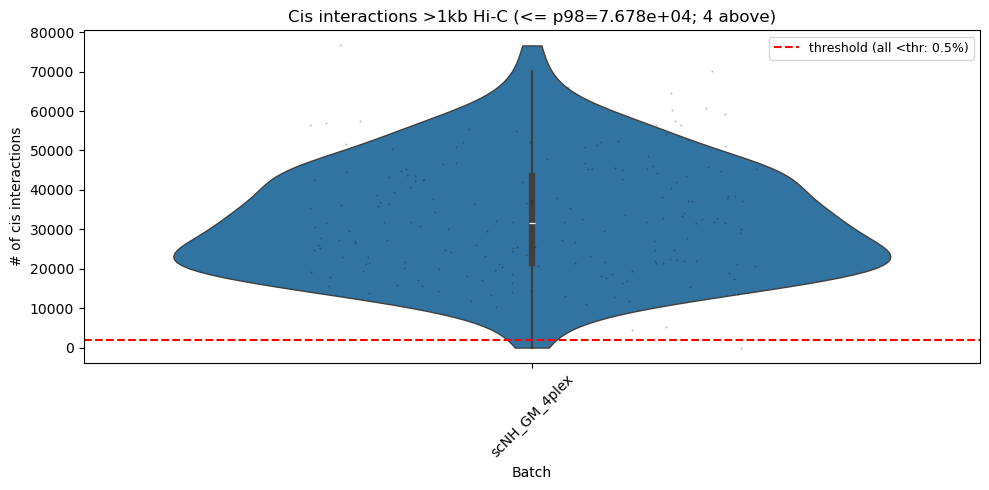

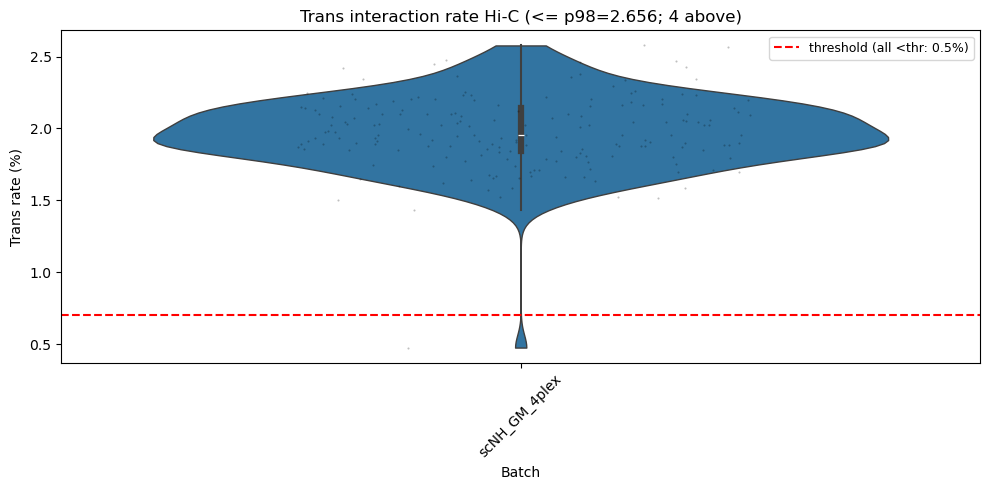

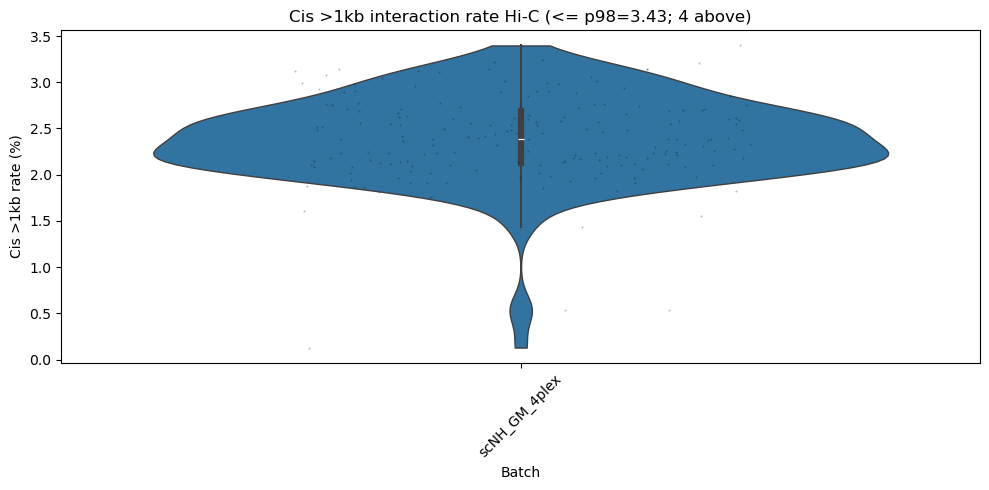

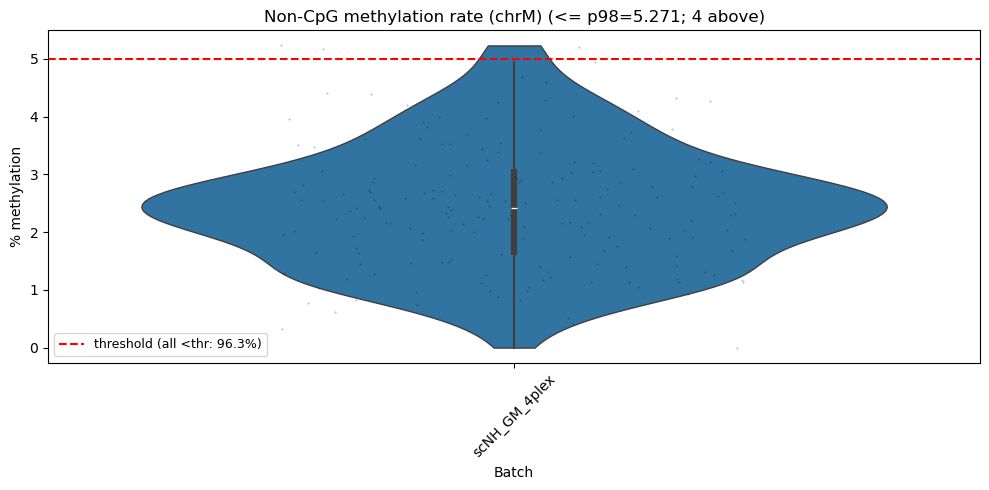

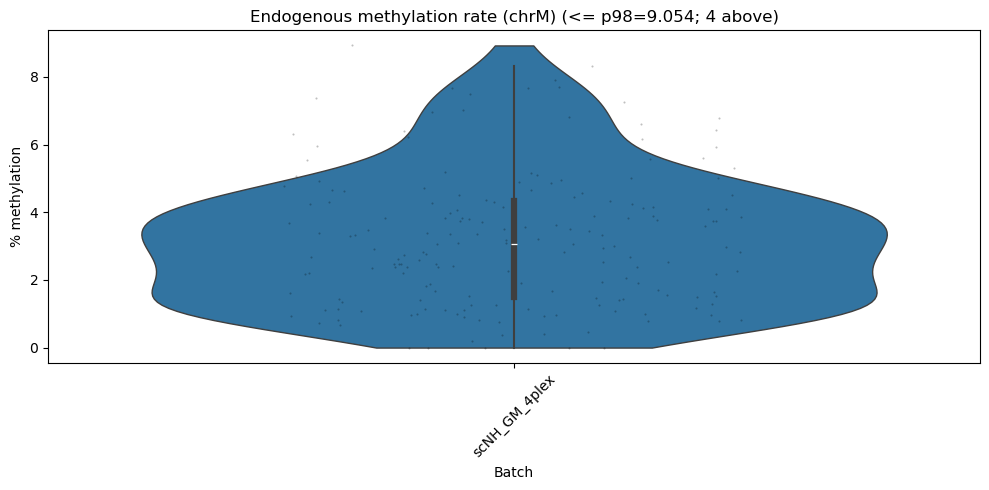

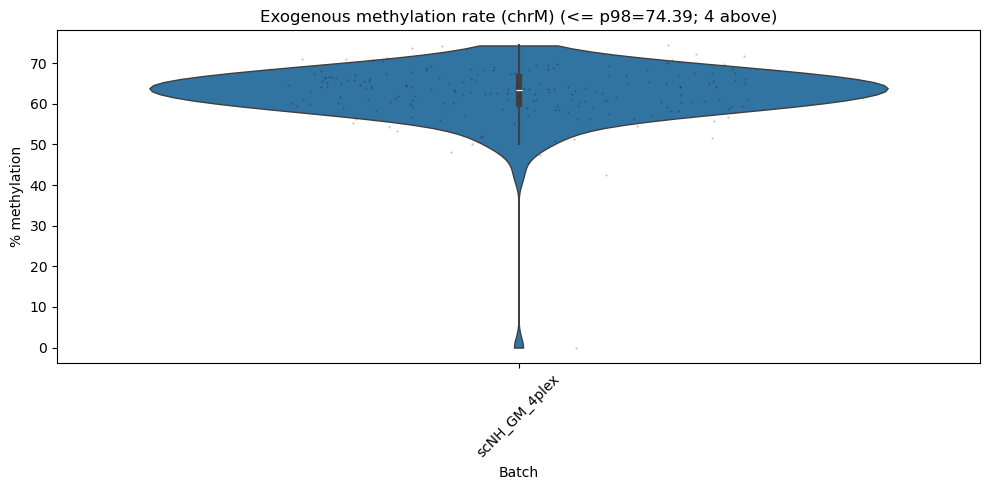

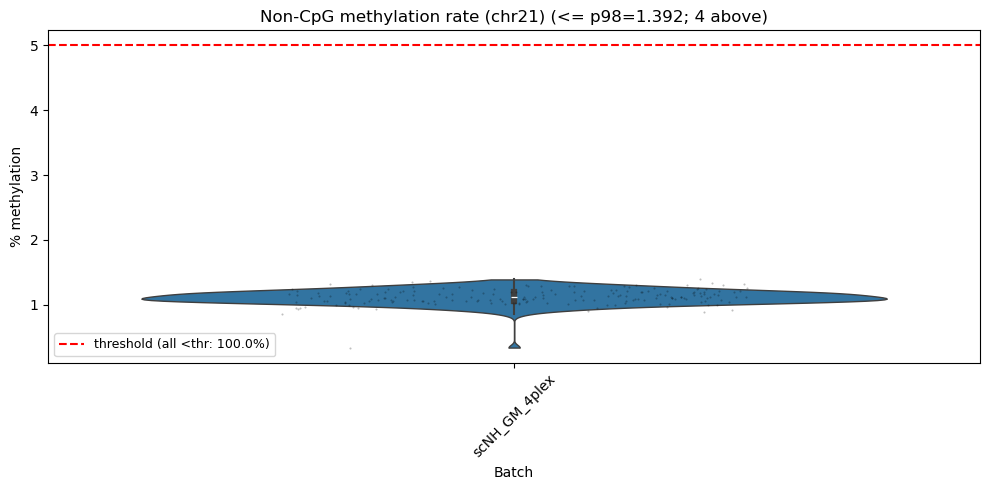

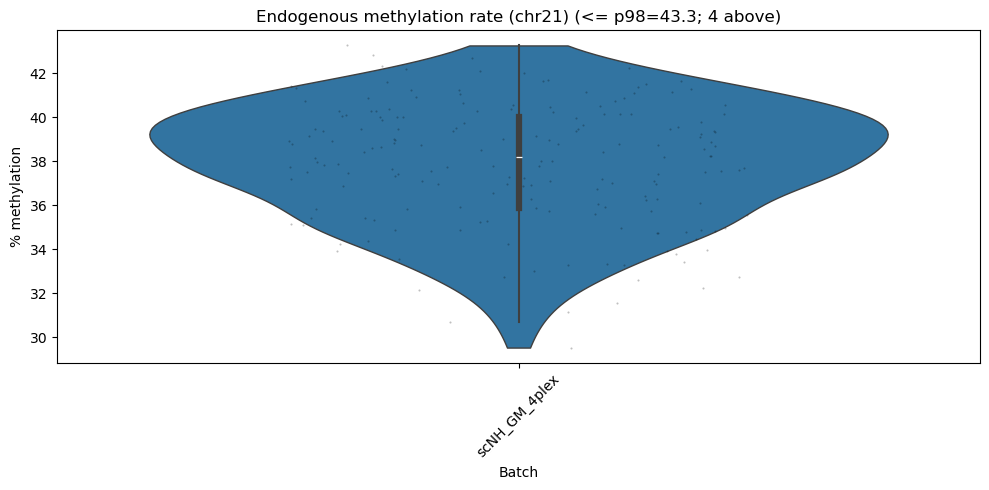

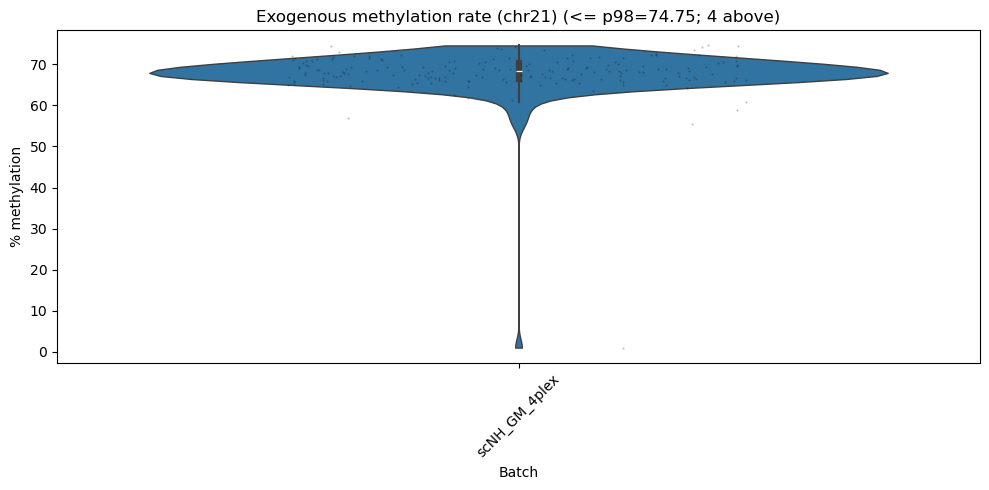

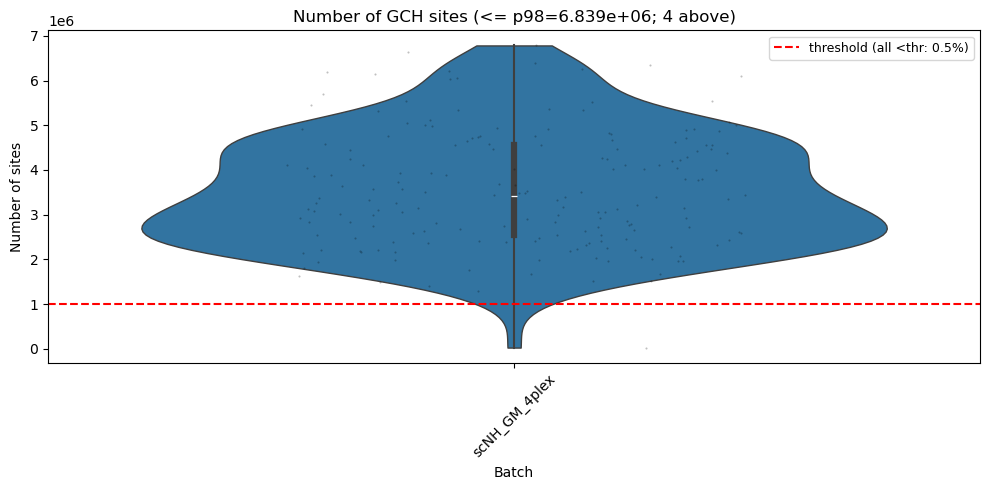

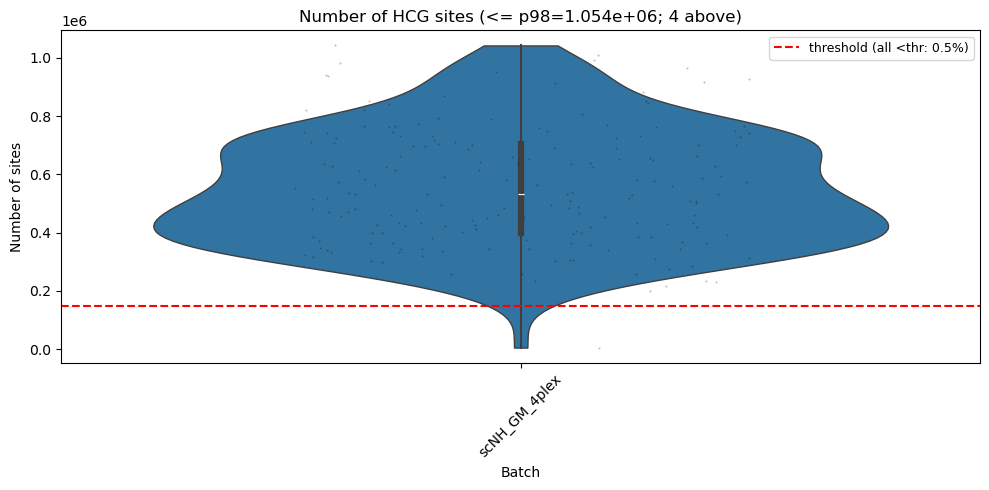

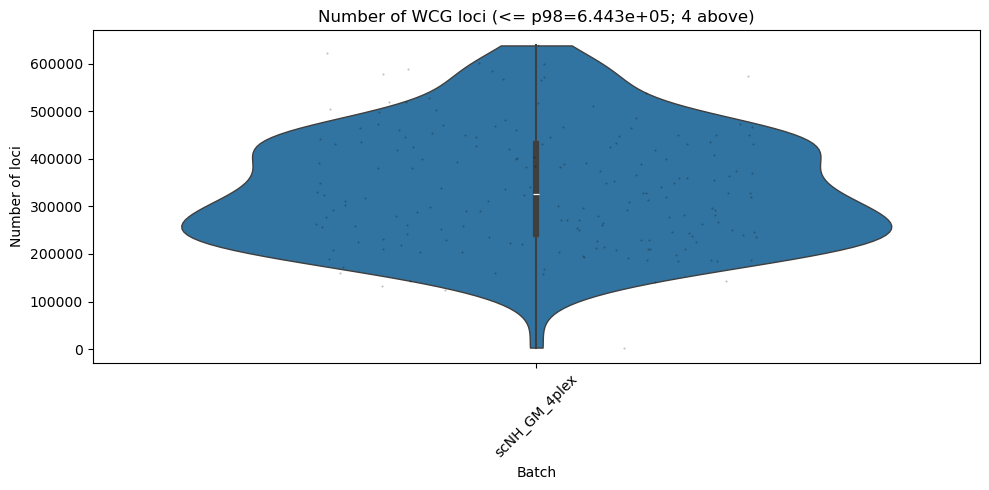

Saved violin plots: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/gm_sc_new/figures/cellline_summary_by_batch_violin_p98_if_outlier.pdf


In [12]:
plot_violins_per_batch(
    df_all_cellline,
    PLOT_COLUMNS,
    METRIC_THRESHOLDS,
    batch_order=batch_order,
    out_pdf=OUT_FIG / 'cellline_summary_by_batch_violin_p98_if_outlier.pdf',
    clip_percentile=98,
    clip_only_if_outlier=True,
    show_inline=True,
)


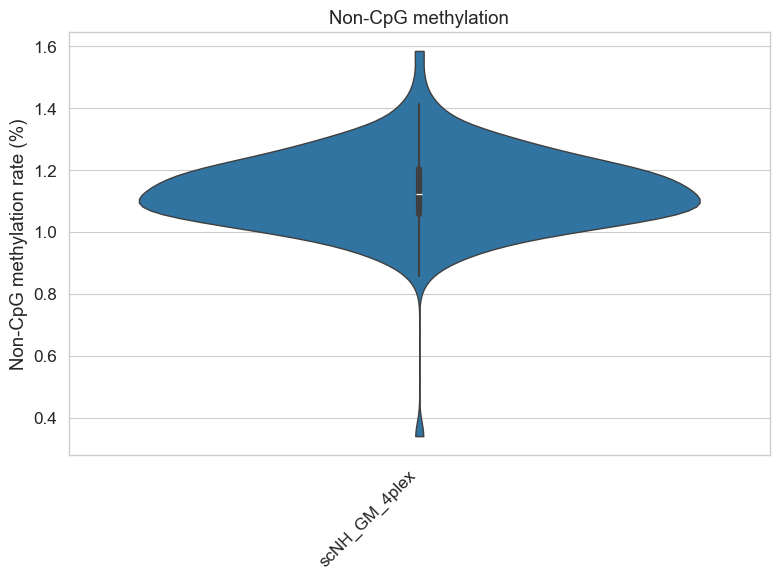

In [13]:
# Publication-style violin: non-CpG methylation
sns.set_context('paper', font_scale=1.4)
sns.set_style('whitegrid')
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

plot_df = df_all_cellline.dropna(subset=['noncpg']).copy()
batch_order = sorted(plot_df['batch'].unique())

plt.figure(figsize=(8, 6))
ax = sns.violinplot(data=plot_df, x='batch', y='noncpg', order=batch_order, inner='box', cut=0)
ax.set_xlabel('')
ax.set_ylabel('Non-CpG methylation rate (%)')
ax.set_title('Non-CpG methylation')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(OUT_FIG / 'noncpg_by_batch.pdf', dpi=300)
plt.savefig(OUT_FIG / 'noncpg_by_batch.png', dpi=300)
plt.show()


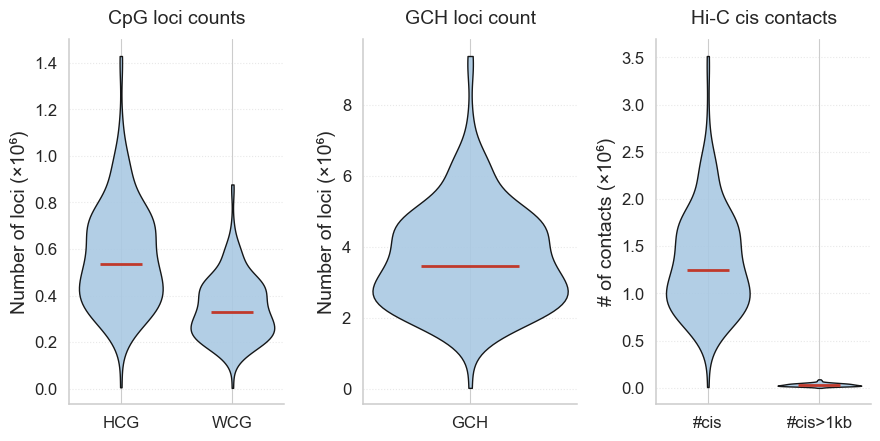

[OK] -> /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/gm_sc_new/figures/cellline_count_violins.pdf


In [14]:
# Count violins, matplotlib-styled (single group, no jitter).
#   panel 1: HCG + WCG loci   panel 2: GCH loci   panel 3: #cis + #cis>1kb
# Values are scaled to round units (x10^3 / x10^6) so there is no axis offset
# label, which keeps every panel title at the same height.
import matplotlib as mpl

PANELS = [
    ('CpG loci counts',   [('HCG', 'HCG'), ('WCG', 'WCG')],            'Number of loci'),
    ('GCH loci count',    [('GCH', 'GCH')],                            'Number of loci'),
    ('Hi-C cis contacts', [('cisnum', '#cis'), ('cis1kbnum', '#cis>1kb')], '# of contacts'),
]


def _scale(maxv):
    if maxv >= 1e6:
        return 1e6, ' (\u00d710\u2076)'
    if maxv >= 1e3:
        return 1e3, ' (\u00d710\u00b3)'
    return 1.0, ''


with mpl.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "font.family": "sans-serif",
                     "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
                     "font.size": 13, "axes.titlesize": 14, "axes.labelsize": 14,
                     "xtick.labelsize": 12, "ytick.labelsize": 12, "axes.linewidth": 1.1,
                     "savefig.dpi": 300, "savefig.bbox": "tight"}):
    fig, axes = plt.subplots(1, len(PANELS), figsize=(3.0 * len(PANELS), 4.6))
    if len(PANELS) == 1:
        axes = [axes]

    for ax, (title, cols, ylabel) in zip(axes, PANELS):
        data, labels = [], []
        for col, lab in cols:
            if col not in df_all_cellline.columns:
                continue
            v = df_all_cellline[col].dropna().values
            if len(v):
                data.append(v)
                labels.append(lab)
        if not data:
            continue
        scale, unit = _scale(max(d.max() for d in data))
        data = [d / scale for d in data]
        pos = np.arange(1, len(data) + 1)
        parts = ax.violinplot(data, positions=pos, widths=0.75,
                              showmedians=True, showextrema=False)
        for b in parts["bodies"]:
            b.set_facecolor("#aac9e3"); b.set_edgecolor("black")
            b.set_alpha(0.9); b.set_linewidth(1.0)
        parts["cmedians"].set_color("#c0392b"); parts["cmedians"].set_linewidth(2.0)

        ax.set_xticks(pos); ax.set_xticklabels(labels)
        ax.set_ylabel(ylabel + unit); ax.set_title(title, y=1.02)
        ax.spines[["top", "right"]].set_visible(False)
        ax.set_axisbelow(True); ax.yaxis.grid(True, ls=":", alpha=0.45)

    fig.tight_layout()
    fig.savefig(OUT_FIG / "cellline_count_violins.pdf")
    fig.savefig(OUT_FIG / "cellline_count_violins.png")
    plt.show()
print("[OK] ->", OUT_FIG / "cellline_count_violins.pdf")


## Cell x bin methylation matrices

Build dense matrices from `08.methylation_snakemake/*.{GCH,HCG}.{bin}_methylation.txt.gz`:
- **rows** = cells
- **columns** = `bin_id`
- **values** = `methylation_level`

Outputs under `QC/methylation_matrices/` (gzip TSV). Set `USE_QC_PASSED_ONLY = True`
to restrict to `cellline_passed.txt`. Available bins here: 1kb, 50kb, 100kb, 250kb.


In [ ]:
METH_BIN_DIR = WORKDIR / '08.methylation_snakemake'
BIN_LABEL = '250kb'
OUT_MATRIX = OUT_QC / 'methylation_matrices'
OUT_MATRIX.mkdir(exist_ok=True)

# Set True to use only QC-passed cells (from cellline_passed.txt)
USE_QC_PASSED_ONLY = False


def _cell_from_methylation_path(path, context, bin_label):
    suffix = f'.{context}.{bin_label}_methylation.txt.gz'
    return Path(path).name[: -len(suffix)]


def build_methylation_matrix(context, bin_label=BIN_LABEL, meth_dir=METH_BIN_DIR, cells=None):
    """Return cells x bins matrix of methylation_level."""
    pattern = f'*.{context}.{bin_label}_methylation.txt.gz'
    files = sorted(meth_dir.glob(pattern))
    if not files:
        raise FileNotFoundError(f'No files matching {pattern} in {meth_dir}')

    if cells is not None:
        cells = set(cells)
        files = [f for f in files if _cell_from_methylation_path(f, context, bin_label) in cells]

    rows = []
    for path in tqdm(files, desc=f'{context} {bin_label}'):
        cell = _cell_from_methylation_path(path, context, bin_label)
        df = pd.read_csv(path, sep='\t', usecols=['bin_id', 'methylation_level'])
        rows.append(df.set_index('bin_id')['methylation_level'].rename(cell))

    mat = pd.concat(rows, axis=1).T
    mat.index.name = 'cell'
    return mat


def save_bin_coords(meth_dir, bin_label, out_path):
    """Save bin coordinates once (same across cells)."""
    ref = next(meth_dir.glob(f'*.GCH.{bin_label}_methylation.txt.gz'))
    coords = pd.read_csv(ref, sep='\t', usecols=['bin_id', 'chr', 'start', 'end'])
    coords.to_csv(out_path, sep='\t', index=False)
    return coords


cells_filter = None
if USE_QC_PASSED_ONLY:
    passed_path = OUT_QC / 'cellline_passed.txt'
    if passed_path.exists():
        cells_filter = pd.read_csv(passed_path, header=None)[0].tolist()
        print(f'Filtering to {len(cells_filter)} QC-passed cells')
    else:
        print('cellline_passed.txt not found; using all cells')

bin_coords_path = OUT_MATRIX / f'bins_{BIN_LABEL}.tsv'
if not bin_coords_path.exists():
    save_bin_coords(METH_BIN_DIR, BIN_LABEL, bin_coords_path)
    print(f'Saved bin coordinates: {bin_coords_path}')

for context in ('GCH', 'HCG'):
    mat = build_methylation_matrix(context, cells=cells_filter)
    out_file = OUT_MATRIX / f'methylation_matrix_{context}_{BIN_LABEL}.tsv.gz'
    mat.to_csv(out_file, sep='\t', compression='gzip')
    print(
        f'{context}: {mat.shape[0]} cells x {mat.shape[1]} bins -> {out_file} '
        f'({out_file.stat().st_size / 1e6:.1f} MB)'
    )
    display(mat.iloc[:3, :5])
